# 04. Основная пара: обучение и оценка

# Методика обучения и оценки

Задача — обучение с учителем, бинарная классификация: GoA=1 (уход)
или GoA=0 (обычная посадка по исходной разметке). Прогноз производится
на C40. Логистическая регрессия здесь является классификатором,
оценивающим вероятность GoA; непрерывную величину ухода не предсказываем.

Основное сравнение: одинаковые события, логистический классификатор с
L2, C=1, без весов классов и подбора гиперпараметров. Вариант без погоды
использует 8 полей; с погодой — 34. Матрица после кодирования шире.
Медианы, стандартизация и one-hot обучаются только на train 2019–2021.
Validation 2022 используется для порогов при FPR 0,1%, 0,5%, 1%; test
2023 — для оценки с зафиксированными порогами. Контролируется сходимость.

Метрики классификации: AP, ROC-AUC, Brier, precision/recall/FPR,
калибровка и срезы по аэропортам, месяцам и покрытию погоды. Модель с
погодой и без погоды оценивается на одинаковых source_row.
Test ранее использовался; доступность признаков ретроспективна и условна.
Практическая пригодность и причинная связь этим сравнением не доказываются.

Первый запуск — основная пара с типом самолета и без маски зазора.
Пары без типа, маска зазора, интервалы по дням и задержки/COR — отдельные
предусмотренные проверки после основного запуска; их отсутствие нельзя
представлять как завершение всего протокола.

Пользователь разрешил обучение 11 октября 2026 года. Перед каждым
будущим запуском явно указывать постановку задачи и семейство метода
в ноутбуке, сценарии запуска и отчете. Разрешение на обучение отменяет
прежний запрет для текущего сравнения, но не открывает закрытые исследования.


## Выполненный запуск

Обучение выполнено scripts/train_primary.py после разрешения пользователя.
Этот ноутбук читает сохраненные модели и прогнозы, проверяет артефакты и
показывает результаты без повторного fit. Код запуска и методика доступны
по ссылкам [train_primary.py](../scripts/train_primary.py) и
[methodology.md](../methodology.md). Результаты относятся к основной паре.


In [1]:
from pathlib import Path
import hashlib,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd(); BASE=ROOT/'research/weather-model-comparison'
m=json.loads((BASE/'reports/04_training_manifest.json').read_text(encoding='utf8'))
assert m['training_executed'] and all(x['converged'] for x in m['models'])
for entry in m['files']:
    with (BASE/'data/primary_models_v1'/entry['file']).open('rb') as f:
        assert hashlib.file_digest(f,'sha256').hexdigest()==entry['sha256']
display(pd.DataFrame(m['models']))
frames=[]
for split in ['validation','test']:
    f=pd.read_csv(BASE/f'reports/04_{split}_evaluation.csv')
    f['split']=split;frames.append(f)
evaluation=pd.concat(frames,ignore_index=True)
overall=evaluation[evaluation.dimension.eq('all')]
display(overall[overall.AP.notna()][['split','model','rows','GoA','AP','ROC_AUC','Brier']])
display(overall[overall.target_validation_FPR.notna()][['split','model','target_validation_FPR','recall','precision','FPR','TP','FP']])


,model,method,train_rows,train_GoA,converged,iterations,seconds,warnings
0,baseline,supervised binary classification / logistic re...,4165060,11626,True,14,6.614797,[]
1,weather,supervised binary classification / logistic re...,4165060,11626,True,18,28.529806,[]


,split,model,rows,GoA,AP,ROC_AUC,Brier
0,validation,baseline,1619848,4984,0.004048,0.581684,0.003067
4,validation,weather,1619848,4984,0.007542,0.630950,0.003063
264,test,baseline,546577,1739,0.003989,0.568153,0.003171
268,test,weather,546577,1739,0.006679,0.608395,0.003168


,split,model,target_validation_FPR,recall,precision,FPR,TP,FP
1,validation,baseline,0.001,0.000803,0.002535,0.000975,4.0,1574.0
2,validation,baseline,0.005,0.009029,0.005547,0.004996,45.0,8068.0
3,validation,baseline,0.010,0.015249,0.004933,0.009493,76.0,15330.0
5,validation,weather,0.001,0.014045,0.042840,0.000969,70.0,1564.0
6,validation,weather,0.005,0.042536,0.025713,0.004974,212.0,8033.0
7,validation,weather,0.010,0.064205,0.019469,0.009980,320.0,16116.0
265,test,baseline,0.001,0.004600,0.003275,0.004469,8.0,2435.0
266,test,baseline,0.005,0.031627,0.005779,0.017368,55.0,9463.0
267,test,baseline,0.010,0.048304,0.004795,0.031999,84.0,17434.0
269,test,weather,0.001,0.008051,0.030702,0.000811,14.0,442.0


## Основные метрики и калибровка

AP оценивает качество ранжирования редкого класса, ROC-AUC — разделение
классов, Brier — ошибку вероятностей. Доля GoA является ориентиром AP
случайного ранжирования. Рост метрик еще не означает практическую пригодность.


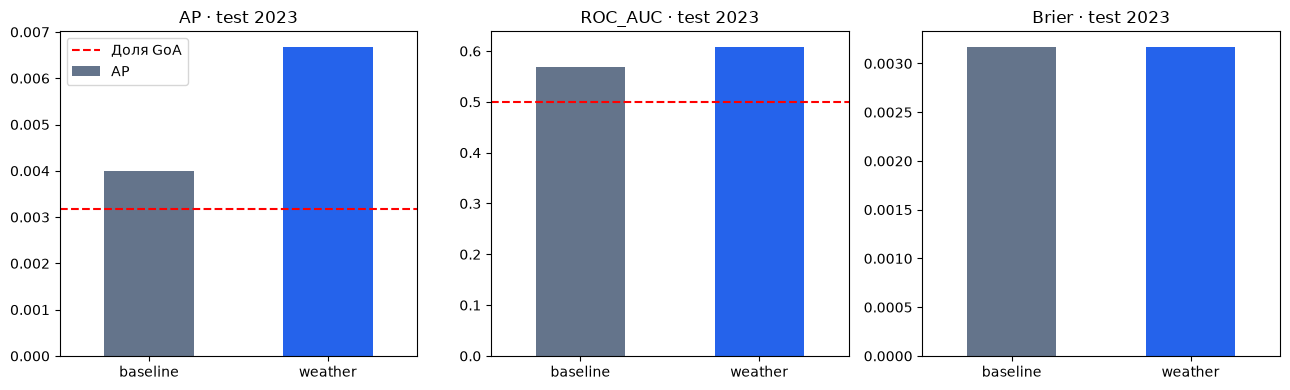

Пока не выполнены: ['no-aircraft pair', 'gap mask pair', 'day bootstrap', 'delay/COR sensitivity']


In [2]:
table=overall[(overall.split=='test')&overall.AP.notna()].set_index('model')
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['AP','ROC_AUC','Brier']):
    table[metric].plot.bar(ax=ax,color=['#64748b','#2563eb'],rot=0)
    ax.set_title(metric+' · test 2023');ax.set_xlabel('')
    if metric=='AP': ax.axhline(1739/546577,color='red',linestyle='--',label='Доля GoA');ax.legend()
    if metric=='ROC_AUC': ax.axhline(.5,color='red',linestyle='--')
fig.tight_layout()
for ext in ['png','svg']:
    path=BASE/f'figures/04_primary_test_metrics.{ext}'
    fig.savefig(path,dpi=160,bbox_inches='tight')
    if ext=='svg': path.write_text('\n'.join(s.rstrip() for s in path.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')
plt.show()
print('Пока не выполнены:',m['pending'])


## Ограничения и продолжение

Test уже использовался ранее; признаки имеют условную доступность.
Дневные интервалы, абляция типа самолета, маска зазора и проверки задержки/COR
еще не выполнены. Полный протокол не завершен. Выигрыш основной пары
следует трактовать как ретроспективный результат для этой выборки.
